
# STRATUM — Random Forest Regression

## Phase 3 — Step 3.3

### Objective

Develop nonlinear virtual metrology models for
mean AlCu film thickness prediction using
Random Forest Regression.

### Research Questions

1. Can nonlinear models outperform bounded Ridge?
2. Does equipment metadata improve Random Forest
   validation performance?
3. How does tree complexity affect generalisation?
4. Does Random Forest mitigate the extreme linear
   extrapolation problem observed previously?
5. Which manufacturing inputs are used most
   extensively by the forest?
6. How does prediction performance vary across
   equipment identifiers?

### Reference Benchmarks

Equipment Mean Regressor:
- Validation MAE: 1.995479
- Validation RMSE: 2.444380

Bounded Ridge Regression:
- APC + Equipment
- Alpha: 10
- Standardisation clipping bound: ±5
- Validation MAE: 1.267788
- Validation RMSE: 1.673137
- Validation R2: 0.530735

### Evaluation Protocol

- Reuse the fixed chronological and lot-aware partitions.
- Fit preprocessing and models using training data only.
- Compare candidate models using validation data.
- Evaluate training-validation performance gaps.
- Retain all validation records.
- Investigate prediction plausibility and maximum errors.
- Reserve the final test partition for Step 3.8.
- Do not use measured metrology outputs as model inputs.

### Important Limitation

Feature importance does not establish physical causality.
Bounded prediction behaviour does not guarantee reliable
predictions for unfamiliar manufacturing conditions.

In [1]:

# STEP 3.3.4 - Imports

from pathlib import Path
import sys
import json
import hashlib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (
    current_dir / "ml" / "random_forest_models.py"
).exists():

    project_root = current_dir

elif (
    current_dir.parent
    / "ml"
    / "random_forest_models.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.data_split import chronological_lot_split

from ml.preprocessing import get_feature_columns

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

from ml.random_forest_models import (
    build_random_forest_model,
    extract_forest_feature_importance,
)

print("STRATUM - Random Forest Regression")
print("Scikit-learn version:", sklearn.__version__)
print("All modules imported successfully!")

STRATUM - Random Forest Regression
Scikit-learn version: 1.9.1
All modules imported successfully!


## 1. Dataset and Split Reproducibility

Verify the original dataset fingerprint, reproduce
the fixed chronological partitions, and validate
the exact APC input schema.

In [2]:

# STEP 3.3.5 - Verify dataset reproducibility

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest_path = (
    project_root
    / "docs"
    / "split_manifest.json"
)

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert (
    current_sha256 == manifest["dataset_sha256"]
), "Dataset fingerprint mismatch."

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,
        test_fraction=manifest["test_fraction"],
        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"]

apc_features, feature_columns = (
    get_feature_columns(df)
)

assert (
    apc_features == manifest["numeric_apc_features"]
)

print("Dataset fingerprint: VERIFIED")
print("Dataset partitioning: VERIFIED")
print("APC feature schema: VERIFIED")

print("\nTraining records:", len(train_df))
print("Validation records:", len(val_df))
print("Reserved test records:", len(test_df))

Dataset fingerprint: VERIFIED
Dataset partitioning: VERIFIED
APC feature schema: VERIFIED

Training records: 3331
Validation records: 834
Reserved test records: 1042


## 2. Reference Benchmark Validation

Load the historical equipment mean baseline and
the best bounded Ridge Regression results.

Verify that both experiments used the same dataset,
prediction target, and validation partition.

In [3]:

# STEP 3.3.6 - Load reference benchmarks

results_dir = (
    project_root / "ml" / "results"
)

baseline_experiment = json.loads(
    (
        results_dir
        / "thickness_baselines.json"
    ).read_text(encoding="utf-8")
)

ridge_experiment = json.loads(
    (
        results_dir
        / "thickness_linear_robustness.json"
    ).read_text(encoding="utf-8")
)

for experiment in [
    baseline_experiment,
    ridge_experiment,
]:

    assert (
        experiment["dataset_sha256"]
        == current_sha256
    )

    assert (
        experiment["evaluation_partition"]
        == "validation"
    )

    assert experiment["target"] == "mean_thickness"

    assert (
        experiment["training_records"]
        == len(train_df)
    )

    assert (
        experiment["validation_records"]
        == len(val_df)
    )

BASELINE_MAE = float(
    baseline_experiment["best_baseline_mae"]
)

RIDGE_MAE = float(
    ridge_experiment["best_model_mae"]
)

RIDGE_RMSE = float(
    ridge_experiment["best_model_rmse"]
)

RIDGE_R2 = float(
    ridge_experiment["best_model_r2"]
)

print("Equipment Mean MAE:", round(BASELINE_MAE, 6))

print("Bounded Ridge MAE:", round(RIDGE_MAE, 6))

print("Bounded Ridge RMSE:", round(RIDGE_RMSE, 6))

print("Bounded Ridge R2:", round(RIDGE_R2, 6))

print("\nReference benchmarks verified!")

Equipment Mean MAE: 1.995479
Bounded Ridge MAE: 1.267788
Bounded Ridge RMSE: 1.673137
Bounded Ridge R2: 0.530735

Reference benchmarks verified!


## 3. Model Input Configuration

Compare APC-only and APC-plus-equipment inputs.

Both configurations use identical training and
validation partitions.

The prediction target is mean film thickness.

In [4]:

# STEP 3.3.7 - Prepare inputs and targets

TARGET = "mean_thickness"

feature_configurations = {
    "APC Only": {
        "columns": apc_features,
        "include_equipment": False,
    },
    "APC + Equipment": {
        "columns": feature_columns,
        "include_equipment": True,
    },
}

y_train = train_df[TARGET].copy()

y_val = val_df[TARGET].copy()

assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()

assert (y_train > 0).all()
assert (y_val > 0).all()

for config_name, config in (
    feature_configurations.items()
):

    columns = config["columns"]

    assert TARGET not in columns
    assert "mean_resistance" not in columns

    print(f"\n{config_name}")

    print(
        "Training shape:",
        train_df[columns].shape
    )

    print(
        "Validation shape:",
        val_df[columns].shape
    )

print(
    "\nTraining target range:",
    y_train.min(),
    "to",
    y_train.max(),
)


APC Only
Training shape: (3331, 110)
Validation shape: (834, 110)

APC + Equipment
Training shape: (3331, 111)
Validation shape: (834, 111)

Training target range: 141.9620738610548 to 163.64180029940047


## 4. Random Forest Experimental Configuration

Evaluate four predefined hyperparameter
configurations using two feature sets.

The experiment investigates the effects of
tree depth, minimum leaf size, and ensemble size.

These are initial controlled experiments rather
than exhaustive hyperparameter optimisation.

In [5]:

# STEP 3.3.8 - Random Forest configurations

forest_configurations = [
    {
        "name": "RF-1 Reference",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
    },
    {
        "name": "RF-2 Moderate",
        "n_estimators": 200,
        "max_depth": 12,
        "min_samples_leaf": 2,
    },
    {
        "name": "RF-3 Regularised",
        "n_estimators": 200,
        "max_depth": 8,
        "min_samples_leaf": 5,
    },
    {
        "name": "RF-4 Larger Ensemble",
        "n_estimators": 400,
        "max_depth": 12,
        "min_samples_leaf": 2,
    },
]

RANDOM_STATE = 42

MAX_FEATURES = 0.7

N_JOBS = -1

display(
    pd.DataFrame(forest_configurations)
)

print(
    "Total planned experiments:",
    len(forest_configurations)
    * len(feature_configurations)
)

,name,n_estimators,max_depth,min_samples_leaf
0,RF-1 Reference,200,NaN,1
1,RF-2 Moderate,200,12.0,2
2,RF-3 Regularised,200,8.0,5
3,RF-4 Larger Ensemble,400,12.0,2


Total planned experiments: 8


## 5. Random Forest Training and Evaluation

Train all predefined Random Forest configurations
using the fixed training partition.

Evaluate training and chronological validation
performance using the reusable regression metrics.

Record computational cost, generalisation gaps,
maximum absolute errors, and prediction validity.

The final test partition remains reserved.

In [6]:

# STEP 3.3.9 - Train Random Forest experiments

forest_results = []

trained_forest_models = {}

validation_predictions = {}

training_predictions = {}

total_experiments = (
    len(feature_configurations)
    * len(forest_configurations)
)

experiment_number = 0

for feature_name, feature_config in (
    feature_configurations.items()
):

    columns = feature_config["columns"]

    X_train = train_df[columns]

    X_val = val_df[columns]

    for forest_config in forest_configurations:

        experiment_number += 1

        model_name = (
            f"{forest_config['name']} ({feature_name})"
        )

        print(
            f"\n[{experiment_number}/{total_experiments}] "
            f"Training {model_name}",
            flush=True,
        )

        pipeline = build_random_forest_model(
            numeric_features=apc_features,
            include_equipment=feature_config[
                "include_equipment"
            ],
            n_estimators=forest_config[
                "n_estimators"
            ],
            max_depth=forest_config[
                "max_depth"
            ],
            min_samples_leaf=forest_config[
                "min_samples_leaf"
            ],
            max_features=MAX_FEATURES,
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS,
        )

        # Fit using training data only
        start_time = time.perf_counter()

        pipeline.fit(
            X_train,
            y_train,
        )

        training_time = (
            time.perf_counter() - start_time
        )

        # Training predictions
        train_pred = pipeline.predict(X_train)

        # Validation predictions
        start_time = time.perf_counter()

        val_pred = pipeline.predict(X_val)

        validation_prediction_time = (
            time.perf_counter() - start_time
        )

        train_metrics = evaluate_regression(
            y_train,
            train_pred,
        )

        val_metrics = evaluate_regression(
            y_val,
            val_pred,
        )

        absolute_errors = np.abs(
            y_val.to_numpy() - val_pred
        )

        max_absolute_error = float(
            absolute_errors.max()
        )

        non_positive_count = int(
            (val_pred <= 0).sum()
        )

        generalisation_gap = (
            val_metrics["MAE"]
            - train_metrics["MAE"]
        )

        forest_results.append({
            "Model": model_name,
            "Algorithm": "Random Forest",
            "Configuration": feature_name,
            "Forest Configuration": forest_config[
                "name"
            ],
            "Trees": forest_config["n_estimators"],
            "Max Depth": forest_config["max_depth"],
            "Min Samples Leaf": forest_config[
                "min_samples_leaf"
            ],
            "Max Features": MAX_FEATURES,
            "Training MAE": train_metrics["MAE"],
            "Training RMSE": train_metrics["RMSE"],
            "Training R2": train_metrics["R2"],
            **val_metrics,
            "Generalisation Gap": generalisation_gap,
            "Maximum Absolute Error": max_absolute_error,
            "P95 Absolute Error": float(
                np.quantile(absolute_errors, 0.95)
            ),
            "Non-Positive Predictions": non_positive_count,
            "Training Time (s)": training_time,
            "Validation Prediction Time (s)": (
                validation_prediction_time
            ),
            "MAE Improvement vs Baseline (%)": (
                calculate_mae_improvement(
                    BASELINE_MAE,
                    val_metrics["MAE"],
                )
            ),
            "MAE Improvement vs Ridge (%)": (
                calculate_mae_improvement(
                    RIDGE_MAE,
                    val_metrics["MAE"],
                )
            ),
        })

        trained_forest_models[model_name] = pipeline

        validation_predictions[model_name] = val_pred

        training_predictions[model_name] = train_pred

        print(
            f"Training MAE: {train_metrics['MAE']:.6f}"
        )

        print(
            f"Validation MAE: {val_metrics['MAE']:.6f}"
        )

        print(
            f"Validation RMSE: {val_metrics['RMSE']:.6f}"
        )

        print(
            f"Validation R2: {val_metrics['R2']:.6f}"
        )

        print(
            f"Training time: {training_time:.2f} seconds"
        )

forest_results_df = (
    pd.DataFrame(forest_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\nAll Random Forest experiments completed.")

display(forest_results_df.round(6))


[1/8] Training RF-1 Reference (APC Only)
Training MAE: 0.409132
Validation MAE: 1.163595
Validation RMSE: 1.535652
Validation R2: 0.604687
Training time: 3.71 seconds

[2/8] Training RF-2 Moderate (APC Only)
Training MAE: 0.644290
Validation MAE: 1.176203
Validation RMSE: 1.542137
Validation R2: 0.601342
Training time: 2.53 seconds

[3/8] Training RF-3 Regularised (APC Only)
Training MAE: 1.009663
Validation MAE: 1.228910
Validation RMSE: 1.602707
Validation R2: 0.569410
Training time: 1.86 seconds

[4/8] Training RF-4 Larger Ensemble (APC Only)
Training MAE: 0.646718
Validation MAE: 1.175128
Validation RMSE: 1.544320
Validation R2: 0.600212
Training time: 4.92 seconds

[5/8] Training RF-1 Reference (APC + Equipment)
Training MAE: 0.403135
Validation MAE: 1.158247
Validation RMSE: 1.529514
Validation R2: 0.607841
Training time: 3.75 seconds

[6/8] Training RF-2 Moderate (APC + Equipment)
Training MAE: 0.644819
Validation MAE: 1.175809
Validation RMSE: 1.547775
Validation R2: 0.598421


,Model,Algorithm,Configuration,Forest Configuration,Trees,Max Depth,Min Samples Leaf,Max Features,Training MAE,Training RMSE,...,MAPE (%),Bias,Generalisation Gap,Maximum Absolute Error,P95 Absolute Error,Non-Positive Predictions,Training Time (s),Validation Prediction Time (s),MAE Improvement vs Baseline (%),MAE Improvement vs Ridge (%)
0,RF-1 Reference (APC + Equipment),Random Forest,APC + Equipment,RF-1 Reference,200,NaN,1,0.7,0.403135,0.542383,...,0.763190,0.028238,0.755112,6.312538,3.057793,0,3.753886,0.113907,41.956454,8.640335
1,RF-1 Reference (APC Only),Random Forest,APC Only,RF-1 Reference,200,NaN,1,0.7,0.409132,0.549420,...,0.766937,0.040909,0.754463,6.536115,3.038177,0,3.712273,0.072484,41.688412,8.218442
2,RF-4 Larger Ensemble (APC Only),Random Forest,APC Only,RF-4 Larger Ensemble,400,12.0,2,0.7,0.646718,0.858883,...,0.774494,0.044937,0.528410,6.635125,3.051741,0,4.921495,0.178495,41.110445,7.308731
3,RF-4 Larger Ensemble (APC + Equipment),Random Forest,APC + Equipment,RF-4 Larger Ensemble,400,12.0,2,0.7,0.643245,0.858510,...,0.774693,0.046542,0.532389,6.551219,3.038378,0,5.224913,0.166989,41.085091,7.268824
4,RF-2 Moderate (APC + Equipment),Random Forest,APC + Equipment,RF-2 Moderate,200,12.0,2,0.7,0.644819,0.860354,...,0.774773,0.046230,0.530990,6.566778,3.011451,0,2.748241,0.098529,41.076335,7.255043
5,RF-2 Moderate (APC Only),Random Forest,APC Only,RF-2 Moderate,200,12.0,2,0.7,0.644290,0.856150,...,0.775251,0.050841,0.531913,6.536406,3.012793,0,2.527400,0.085066,41.056603,7.223983
6,RF-3 Regularised (APC Only),Random Forest,APC Only,RF-3 Regularised,200,8.0,5,0.7,1.009663,1.332399,...,0.810065,0.069926,0.219248,6.931820,3.025789,0,1.858283,0.093138,38.415252,3.066537
7,RF-3 Regularised (APC + Equipment),Random Forest,APC + Equipment,RF-3 Regularised,200,8.0,5,0.7,1.002731,1.325992,...,0.813855,0.086173,0.231840,6.854129,3.042481,0,2.179212,0.108325,38.131569,2.620025


## 6. Random Forest Model Comparison

Compare validation performance across all eight
Random Forest experiments.

Evaluate MAE, RMSE, R2, MAPE, prediction bias,
maximum absolute error, and non-positive predictions.

Use validation MAE as the primary ranking metric
among candidates with physically plausible outputs.

In [7]:

# STEP 3.3.10 - Compare experiment results

comparison_columns = [
    "Model",
    "Training MAE",
    "MAE",
    "RMSE",
    "R2",
    "MAPE (%)",
    "Bias",
    "Maximum Absolute Error",
    "Non-Positive Predictions",
    "MAE Improvement vs Baseline (%)",
    "MAE Improvement vs Ridge (%)",
]

display(
    forest_results_df[comparison_columns]
    .round(6)
)

eligible_results = forest_results_df.loc[
    forest_results_df[
        "Non-Positive Predictions"
    ] == 0
]

if eligible_results.empty:

    raise ValueError(
        "No physically plausible Random Forest "
        "candidate was found."
    )

best_result = (
    eligible_results
    .sort_values("MAE")
    .iloc[0]
)

best_model_name = best_result["Model"]

best_pipeline = (
    trained_forest_models[best_model_name]
)

best_predictions = (
    validation_predictions[best_model_name]
)

best_train_predictions = (
    training_predictions[best_model_name]
)

best_metrics = evaluate_regression(
    y_val,
    best_predictions,
)

print("\nBest preliminary Random Forest candidate:")
print(best_model_name)

print("\nValidation metrics:")

display(
    pd.DataFrame(
        [best_metrics]
    ).round(6)
)

print(
    "MAE improvement vs equipment baseline:",
    round(
        best_result[
            "MAE Improvement vs Baseline (%)"
        ],
        4,
    ),
    "%",
)

print(
    "MAE improvement vs bounded Ridge:",
    round(
        best_result[
            "MAE Improvement vs Ridge (%)"
        ],
        4,
    ),
    "%",
)

,Model,Training MAE,MAE,RMSE,R2,MAPE (%),Bias,Maximum Absolute Error,Non-Positive Predictions,MAE Improvement vs Baseline (%),MAE Improvement vs Ridge (%)
0,RF-1 Reference (APC + Equipment),0.403135,1.158247,1.529514,0.607841,0.763190,0.028238,6.312538,0,41.956454,8.640335
1,RF-1 Reference (APC Only),0.409132,1.163595,1.535652,0.604687,0.766937,0.040909,6.536115,0,41.688412,8.218442
2,RF-4 Larger Ensemble (APC Only),0.646718,1.175128,1.544320,0.600212,0.774494,0.044937,6.635125,0,41.110445,7.308731
3,RF-4 Larger Ensemble (APC + Equipment),0.643245,1.175634,1.549086,0.597741,0.774693,0.046542,6.551219,0,41.085091,7.268824
4,RF-2 Moderate (APC + Equipment),0.644819,1.175809,1.547775,0.598421,0.774773,0.046230,6.566778,0,41.076335,7.255043
5,RF-2 Moderate (APC Only),0.644290,1.176203,1.542137,0.601342,0.775251,0.050841,6.536406,0,41.056603,7.223983
6,RF-3 Regularised (APC Only),1.009663,1.228910,1.602707,0.569410,0.810065,0.069926,6.931820,0,38.415252,3.066537
7,RF-3 Regularised (APC + Equipment),1.002731,1.234571,1.608874,0.566091,0.813855,0.086173,6.854129,0,38.131569,2.620025



Best preliminary Random Forest candidate:
RF-1 Reference (APC + Equipment)

Validation metrics:


,MAE,RMSE,R2,MAPE (%),Bias
0,1.158247,1.529514,0.607841,0.76319,0.028238


MAE improvement vs equipment baseline: 41.9565 %
MAE improvement vs bounded Ridge: 8.6403 %


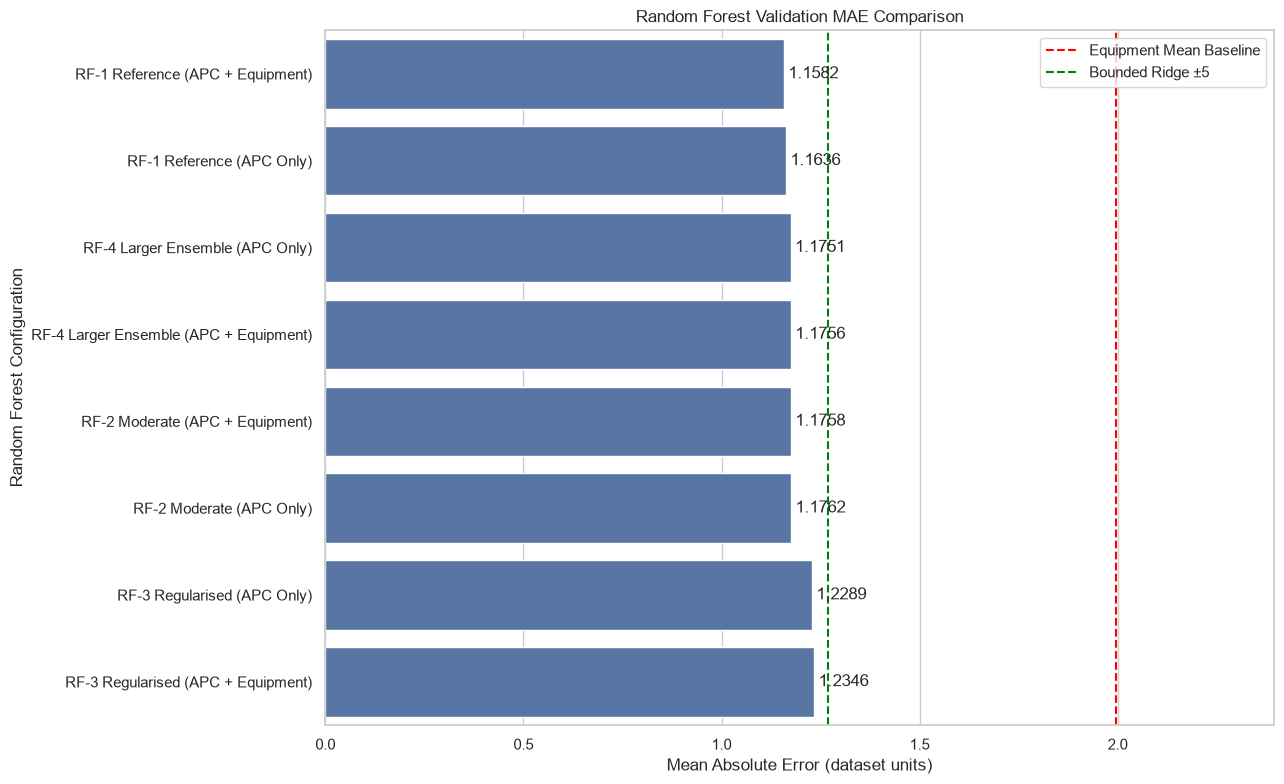

In [8]:

# Compare Random Forest validation MAE

plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=forest_results_df,
    x="MAE",
    y="Model",
)

ax.axvline(
    BASELINE_MAE,
    color="red",
    linestyle="--",
    label="Equipment Mean Baseline",
)

ax.axvline(
    RIDGE_MAE,
    color="green",
    linestyle="--",
    label="Bounded Ridge ±5",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.4f",
    padding=3,
)

plt.xlim(
    0,
    max(
        BASELINE_MAE,
        RIDGE_MAE,
        forest_results_df["MAE"].max(),
    ) * 1.2,
)

plt.title(
    "Random Forest Validation MAE Comparison"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Random Forest Configuration")

plt.legend()
plt.tight_layout()
plt.show()


## 7. Training-Validation Generalisation Analysis

Compare training and validation errors across
Random Forest configurations.

Investigate whether increased tree complexity
reduces training error without improving
chronological validation performance.

The observed generalisation gap may reflect both
model overfitting and temporal distribution shifts.

,Model,Training MAE,Validation MAE,Training R2,Validation R2,Generalisation Gap
0,RF-1 Reference (APC + Equipment),0.403135,1.158247,0.952383,0.607841,0.755112
1,RF-1 Reference (APC Only),0.409132,1.163595,0.951139,0.604687,0.754463
2,RF-4 Larger Ensemble (APC Only),0.646718,1.175128,0.880596,0.600212,0.528410
3,RF-4 Larger Ensemble (APC + Equipment),0.643245,1.175634,0.880700,0.597741,0.532389
4,RF-2 Moderate (APC + Equipment),0.644819,1.175809,0.880187,0.598421,0.530990
5,RF-2 Moderate (APC Only),0.644290,1.176203,0.881355,0.601342,0.531913
6,RF-3 Regularised (APC Only),1.009663,1.228910,0.712645,0.569410,0.219248
7,RF-3 Regularised (APC + Equipment),1.002731,1.234571,0.715402,0.566091,0.231840


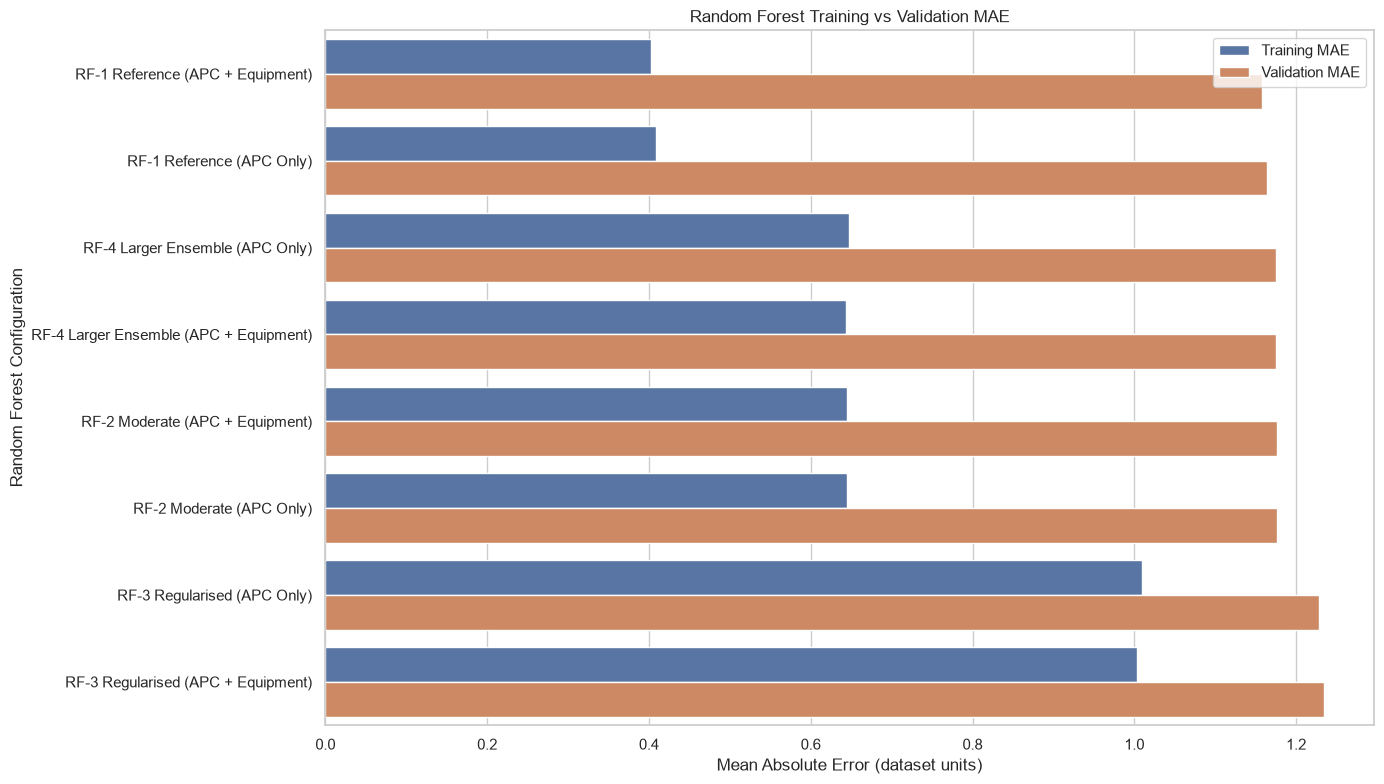

In [9]:

# STEP 3.3.11 - Generalisation gap analysis

generalisation_summary = forest_results_df[
    [
        "Model",
        "Training MAE",
        "MAE",
        "Training R2",
        "R2",
        "Generalisation Gap",
    ]
].copy()

generalisation_summary = (
    generalisation_summary.rename(
        columns={
            "MAE": "Validation MAE",
            "R2": "Validation R2",
        }
    )
)

display(
    generalisation_summary.round(6)
)

generalisation_plot_data = (
    generalisation_summary.melt(
        id_vars=["Model"],
        value_vars=[
            "Training MAE",
            "Validation MAE",
        ],
        var_name="Partition",
        value_name="MAE",
    )
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=generalisation_plot_data,
    x="MAE",
    y="Model",
    hue="Partition",
)

plt.title(
    "Random Forest Training vs Validation MAE"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Random Forest Configuration")

plt.legend()
plt.tight_layout()
plt.show()

## 8. Equipment Metadata Ablation Analysis

Compare matching Random Forest configurations
with and without explicit equipment metadata.

Keep tree hyperparameters and data partitions
unchanged across the paired comparisons.

Ablation results measure predictive usefulness,
not causal equipment effects.

Configuration,APC + Equipment,APC Only,Equipment MAE Improvement (%)
Forest Configuration,,,
RF-1 Reference,1.158247,1.163595,0.459671
RF-2 Moderate,1.175809,1.176203,0.033478
RF-3 Regularised,1.234571,1.228910,-0.460638
RF-4 Larger Ensemble,1.175634,1.175128,-0.043054


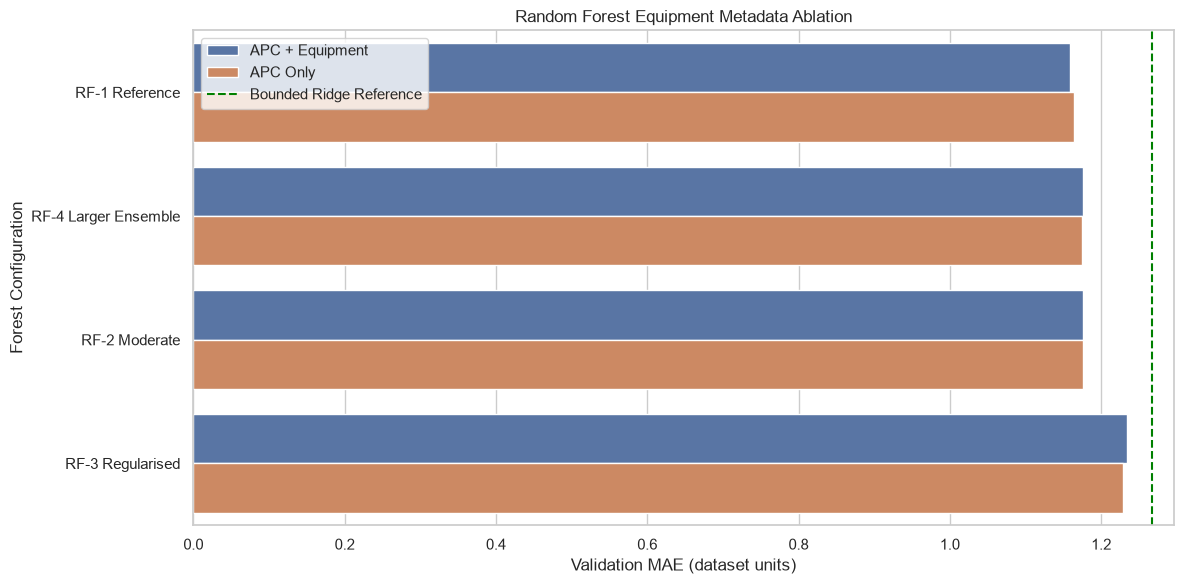

In [10]:

# STEP 3.3.12 - Equipment metadata ablation

equipment_ablation = (
    forest_results_df.pivot(
        index="Forest Configuration",
        columns="Configuration",
        values="MAE",
    )
)

equipment_ablation[
    "Equipment MAE Improvement (%)"
] = (
    (
        equipment_ablation["APC Only"]
        - equipment_ablation["APC + Equipment"]
    )
    / equipment_ablation["APC Only"]
    * 100
)

display(
    equipment_ablation.round(6)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=forest_results_df,
    x="MAE",
    y="Forest Configuration",
    hue="Configuration",
)

plt.axvline(
    RIDGE_MAE,
    color="green",
    linestyle="--",
    label="Bounded Ridge Reference",
)

plt.title(
    "Random Forest Equipment Metadata Ablation"
)

plt.xlabel("Validation MAE (dataset units)")
plt.ylabel("Forest Configuration")

plt.legend()
plt.tight_layout()
plt.show()

## 9. Cross-Model Benchmark Comparison

Compare the best preliminary Random Forest
candidate with the historical equipment mean
baseline and bounded Ridge Regression.

Assess average errors, large-error sensitivity,
and explained target variation.

,Model,MAE,RMSE,R2,MAPE (%),Bias
0,Best Random Forest,1.158247,1.529514,0.607841,0.763190,0.028238
1,Bounded Ridge ±5,1.267788,1.673137,0.530735,0.834860,-0.121325
2,Equipment Mean,1.995479,2.444380,-0.001596,1.320842,0.664447


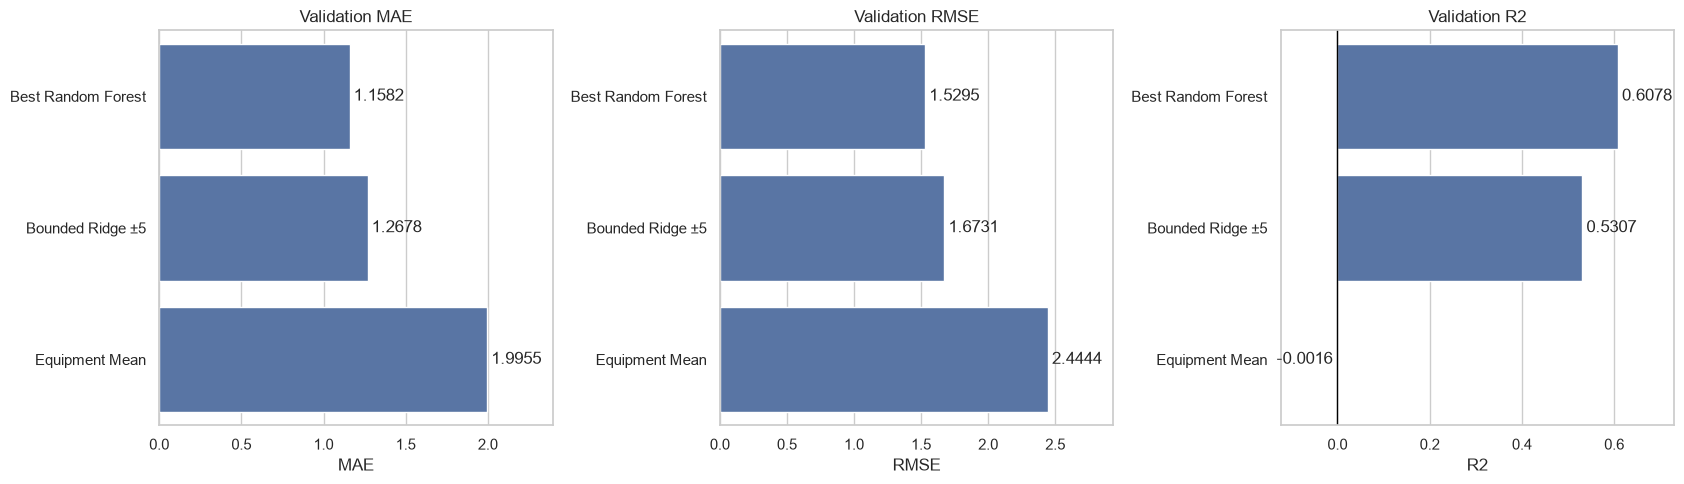

In [11]:

# STEP 3.3.13 - Cross-model comparison

equipment_baseline_result = next(
    result
    for result in baseline_experiment["results"]
    if result["Model"]
    == baseline_experiment["best_baseline"]
)

ridge_best_result = next(
    result
    for result in ridge_experiment["results"]
    if result["Model"]
    == ridge_experiment["best_model"]
)

benchmark_comparison = pd.DataFrame([
    {
        "Model": "Equipment Mean",
        "MAE": equipment_baseline_result["MAE"],
        "RMSE": equipment_baseline_result["RMSE"],
        "R2": equipment_baseline_result["R2"],
        "MAPE (%)": equipment_baseline_result[
            "MAPE (%)"
        ],
        "Bias": equipment_baseline_result["Bias"],
    },
    {
        "Model": "Bounded Ridge ±5",
        "MAE": ridge_best_result["MAE"],
        "RMSE": ridge_best_result["RMSE"],
        "R2": ridge_best_result["R2"],
        "MAPE (%)": ridge_best_result["MAPE (%)"],
        "Bias": ridge_best_result["Bias"],
    },
    {
        "Model": "Best Random Forest",
        **best_metrics,
    },
])

benchmark_comparison = (
    benchmark_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    benchmark_comparison.round(6)
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
)

for ax, metric in zip(
    axes,
    ["MAE", "RMSE", "R2"],
):

    sns.barplot(
        data=benchmark_comparison,
        x=metric,
        y="Model",
        ax=ax,
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.4f",
        padding=3,
    )

    ax.set_title(f"Validation {metric}")

    ax.set_ylabel("")

    if metric == "R2":

        ax.axvline(
            0,
            color="black",
            linewidth=1,
        )

    ax.margins(x=0.2)

plt.tight_layout()
plt.show()

## 10. Prediction and Residual Analysis

Examine actual versus predicted thickness,
residual distributions, and residual patterns
for the best Random Forest candidate.

Investigate prediction accuracy, systematic bias,
large errors, and regression toward the mean.

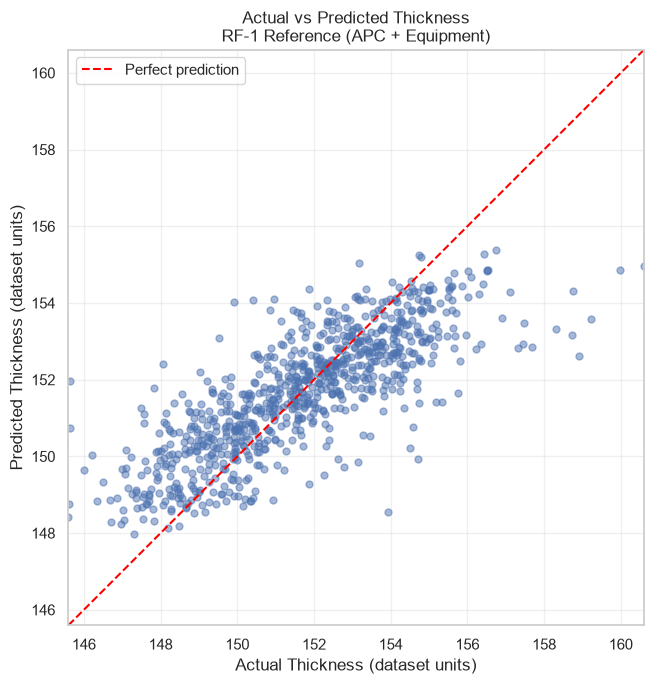

In [12]:

# Actual versus predicted thickness

lower = min(
    y_val.min(),
    best_predictions.min(),
)

upper = max(
    y_val.max(),
    best_predictions.max(),
)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    best_predictions,
    alpha=0.5,
    s=25,
)

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Perfect prediction",
)

plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.gca().set_aspect(
    "equal",
    adjustable="box",
)

plt.title(
    f"Actual vs Predicted Thickness\n{best_model_name}"
)

plt.xlabel("Actual Thickness (dataset units)")
plt.ylabel("Predicted Thickness (dataset units)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

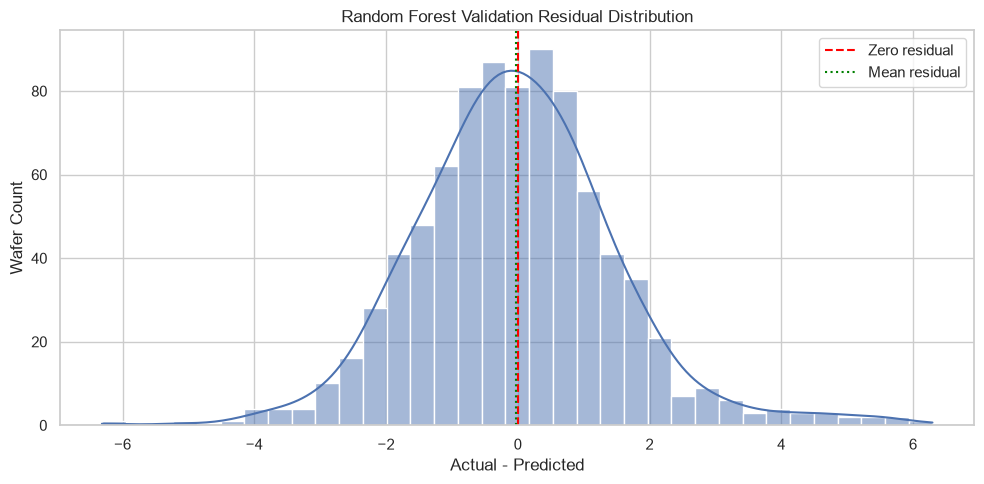

In [13]:

# Residual distribution

residuals = (
    y_val.to_numpy()
    - best_predictions
)

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=35,
    kde=True,
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero residual",
)

plt.axvline(
    residuals.mean(),
    color="green",
    linestyle=":",
    label="Mean residual",
)

plt.title(
    "Random Forest Validation Residual Distribution"
)

plt.xlabel("Actual - Predicted")
plt.ylabel("Wafer Count")

plt.legend()
plt.tight_layout()
plt.show()

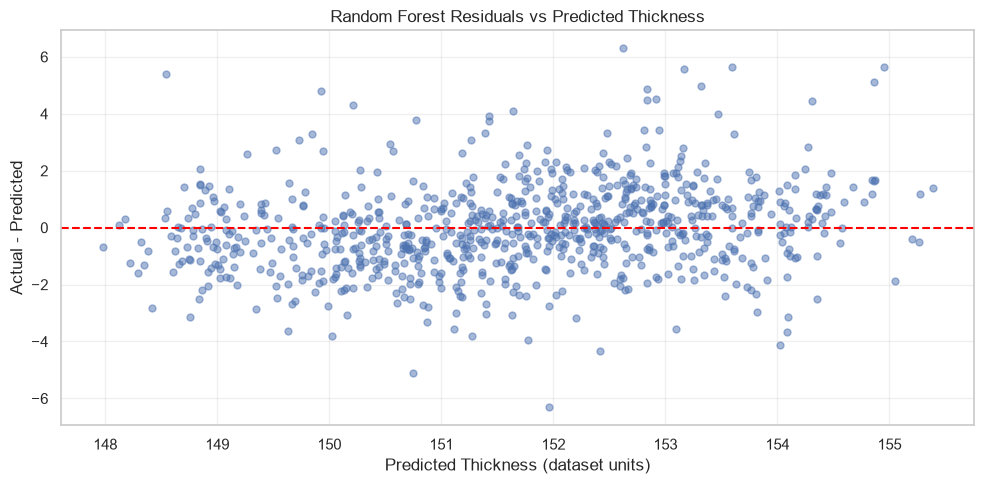

In [14]:

# Residuals versus predicted values

plt.figure(figsize=(10, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5,
    s=25,
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
)

plt.title(
    "Random Forest Residuals vs Predicted Thickness"
)

plt.xlabel("Predicted Thickness (dataset units)")
plt.ylabel("Actual - Predicted")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

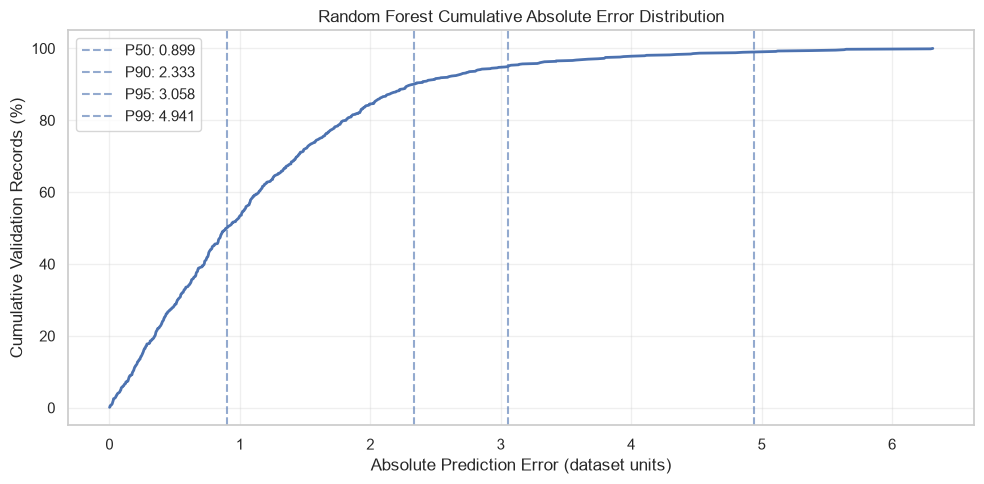

Absolute error percentiles:
P50: 0.899015
P90: 2.333019
P95: 3.057793
P99: 4.940939
P100: 6.312538


In [15]:

# Cumulative distribution of absolute errors

absolute_errors = np.abs(residuals)

sorted_errors = np.sort(absolute_errors)

cumulative_percentage = (
    np.arange(1, len(sorted_errors) + 1)
    / len(sorted_errors)
    * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    sorted_errors,
    cumulative_percentage,
    linewidth=2,
)

for percentile in [50, 90, 95, 99]:

    error_value = np.percentile(
        absolute_errors,
        percentile,
    )

    plt.axvline(
        error_value,
        linestyle="--",
        alpha=0.6,
        label=f"P{percentile}: {error_value:.3f}",
    )

plt.title(
    "Random Forest Cumulative Absolute Error Distribution"
)

plt.xlabel("Absolute Prediction Error (dataset units)")
plt.ylabel("Cumulative Validation Records (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Absolute error percentiles:")

for percentile in [50, 90, 95, 99, 100]:

    print(
        f"P{percentile}: "
        f"{np.percentile(absolute_errors, percentile):.6f}"
    )


## 11. Prediction Robustness Investigation

Verify finite and positive Random Forest predictions.

Examine whether predicted thickness remains within
the training target range.

Investigate prediction behaviour for the two wafer
records previously associated with catastrophic
linear extrapolation.

Prediction range compliance does not independently
establish predictive accuracy or engineering quality.

In [16]:

# STEP 3.3.15A - Verify prediction robustness

training_target_min = float(y_train.min())

training_target_max = float(y_train.max())

range_tolerance = (
    max(
        1.0,
        abs(training_target_min),
        abs(training_target_max),
    ) * 1e-10
)

robustness_summary = []

for model_name, predictions in (
    validation_predictions.items()
):

    assert len(predictions) == len(y_val)

    assert np.isfinite(predictions).all()

    outside_training_range = (
        (
            predictions
            < training_target_min - range_tolerance
        )
        |
        (
            predictions
            > training_target_max + range_tolerance
        )
    )

    robustness_summary.append({
        "Model": model_name,
        "Minimum Prediction": float(
            predictions.min()
        ),
        "Maximum Prediction": float(
            predictions.max()
        ),
        "Non-Positive Predictions": int(
            (predictions <= 0).sum()
        ),
        "Outside Training Target Range": int(
            outside_training_range.sum()
        ),
    })

    assert not outside_training_range.any()

    assert (predictions > 0).all()

robustness_summary_df = pd.DataFrame(
    robustness_summary
)

print(
    "Training target minimum:",
    training_target_min
)

print(
    "Training target maximum:",
    training_target_max
)

display(
    robustness_summary_df.round(6)
)

print("\nPrediction range checks: PASSED")

Training target minimum: 141.9620738610548
Training target maximum: 163.64180029940047


,Model,Minimum Prediction,Maximum Prediction,Non-Positive Predictions,Outside Training Target Range
0,RF-1 Reference (APC Only),147.737005,155.401183,0,0
1,RF-2 Moderate (APC Only),147.919483,155.390287,0,0
2,RF-3 Regularised (APC Only),147.956704,155.037191,0,0
3,RF-4 Larger Ensemble (APC Only),147.897592,155.323403,0,0
4,RF-1 Reference (APC + Equipment),147.978819,155.383991,0,0
5,RF-2 Moderate (APC + Equipment),148.022258,155.312392,0,0
6,RF-3 Regularised (APC + Equipment),148.051777,155.092323,0,0
7,RF-4 Larger Ensemble (APC + Equipment),147.914839,155.344403,0,0



Prediction range checks: PASSED


In [17]:

# STEP 3.3.15B - Revisit previous failure cases

previous_problem_wafer_ids = [
    "V6G022UK04",
    "V6G01XL921",
]

failure_case_df = val_df[
    [
        "wafer_id",
        "equipment",
        "runstart",
        TARGET,
    ]
].copy()

failure_case_df["Random Forest Prediction"] = (
    best_predictions
)

failure_case_df["Absolute Error"] = (
    failure_case_df[TARGET]
    - failure_case_df["Random Forest Prediction"]
).abs()

previous_failure_cases = (
    failure_case_df.loc[
        failure_case_df["wafer_id"].isin(
            previous_problem_wafer_ids
        )
    ].copy()
)

assert len(previous_failure_cases) == 2

display(
    previous_failure_cases.round({
        TARGET: 6,
        "Random Forest Prediction": 6,
        "Absolute Error": 6,
    })
)

,wafer_id,equipment,runstart,mean_thickness,Random Forest Prediction,Absolute Error
717,V6G022UK04,equipment_1,2024-06-23 16:38:19,149.381522,149.950916,0.569394
720,V6G01XL921,equipment_14,2024-06-24 11:24:52,148.487949,149.164761,0.676812


## 12. Input Distribution Diagnostics

Apply the previous training-standardised sensor
warning heuristic to Random Forest validation records.

Compare prediction errors between records with
and without numerical input warnings.

This analysis evaluates an exploratory warning
heuristic, not a calibrated uncertainty estimator
or an official process acceptance threshold.

In [18]:

# STEP 3.3.16 - Input warning diagnostic

from ml.preprocessing import build_preprocessor

diagnostic_preprocessor = build_preprocessor(
    numeric_features=apc_features,
    include_equipment=False,
    scale_numeric=True,
    clip_z=None,
)

# Fit diagnostic transformation on training data
diagnostic_preprocessor.fit(
    train_df[apc_features]
)

diagnostic_z = diagnostic_preprocessor.transform(
    val_df[apc_features]
)

# Original APC measurements appear before indicators
sensor_z = diagnostic_z[
    :,
    :len(apc_features)
]

WARNING_BOUND = 5.0

sensor_warning_flags = (
    np.abs(sensor_z) > WARNING_BOUND
)

warning_error_df = pd.DataFrame({
    "equipment": val_df["equipment"].to_numpy(),
    "Actual": y_val.to_numpy(),
    "Predicted": best_predictions,
    "Flagged Sensors": (
        sensor_warning_flags.sum(axis=1)
    ),
    "Maximum Absolute Sensor Z": (
        np.abs(sensor_z).max(axis=1)
    ),
})

warning_error_df["Sensor Warning"] = (
    warning_error_df["Flagged Sensors"] > 0
)

warning_error_df["Absolute Error"] = (
    warning_error_df["Actual"]
    - warning_error_df["Predicted"]
).abs()

warning_error_df["Squared Error"] = (
    warning_error_df["Absolute Error"] ** 2
)

warning_summary = (
    warning_error_df
    .groupby("Sensor Warning")
    .agg(
        Records=("Actual", "count"),
        MAE=("Absolute Error", "mean"),
        MSE=("Squared Error", "mean"),
        Maximum_Error=("Absolute Error", "max"),
    )
)

warning_summary["RMSE"] = np.sqrt(
    warning_summary.pop("MSE")
)

display(
    warning_summary.round(6)
)

print(
    "Records with sensor warnings:",
    int(
        warning_error_df["Sensor Warning"].sum()
    )
)

print(
    "Records without sensor warnings:",
    int(
        (~warning_error_df["Sensor Warning"]).sum()
    )
)

,Records,MAE,Maximum_Error,RMSE
Sensor Warning,,,,
False,173,1.196212,6.312538,1.575503
True,661,1.148310,6.295494,1.517248


Records with sensor warnings: 661
Records without sensor warnings: 173


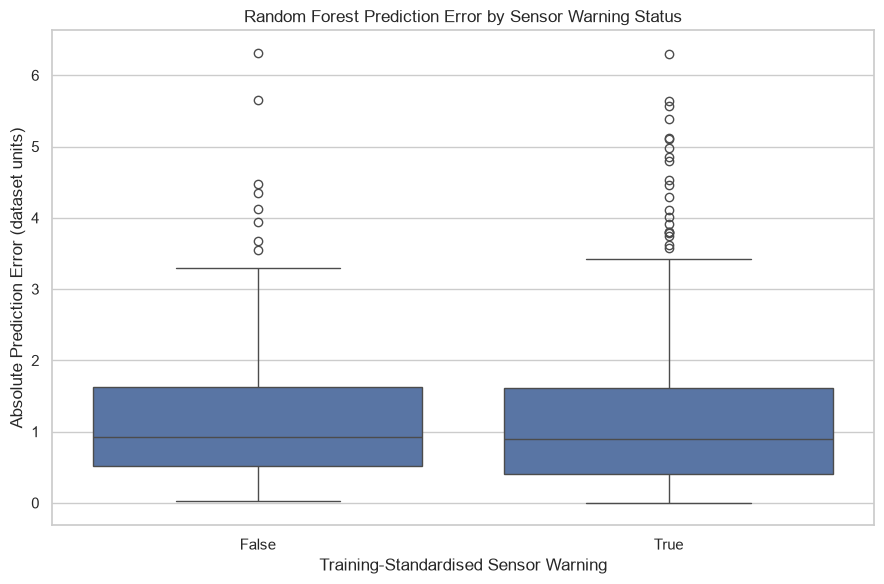

In [19]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=warning_error_df,
    x="Sensor Warning",
    y="Absolute Error",
    order=[False, True],
)

plt.title(
    "Random Forest Prediction Error by Sensor Warning Status"
)

plt.xlabel("Training-Standardised Sensor Warning")
plt.ylabel("Absolute Prediction Error (dataset units)")

plt.tight_layout()
plt.show()

## 13. Random Forest Feature Importance

Extract impurity-based importance scores from
the selected Random Forest pipeline.

Examine which transformed process variables,
missingness indicators, and equipment encodings
contribute to decision-tree splitting.

Impurity-based importance may be biased and can
distribute importance among correlated features.

It must not be interpreted as causal process evidence.

In [20]:

# STEP 3.3.17 - Feature importance

importance_df = extract_forest_feature_importance(
    best_pipeline
)

print(
    "Transformed feature count:",
    len(importance_df)
)

print(
    "Total feature importance:",
    importance_df["Importance"].sum()
)

display(
    importance_df.head(20).round(6)
)

Transformed feature count: 173
Total feature importance: 0.9999999999999999


,Feature,Importance
0,numeric__T_DEP1_PROCESS,0.114291
1,numeric__LIFE_TARGET_RUN_A,0.081375
2,numeric__T_RECIPE_ENG,0.058350
3,numeric__UTILISATION_TARGET_RUN_A,0.037009
4,numeric__LIFE_TARGET_DEP1_A,0.033058
5,numeric__LIFE_TARGET_DEP1_S,0.032949
6,numeric__RGA_FUNCTION_DAY,0.024216
7,numeric__VOLTS_TARGET_RUN_A,0.022105
8,numeric__VOLTS_TARGET_RE_A,0.021094
9,numeric__AMPS_TARGET_20_90_DEP1_X,0.018880


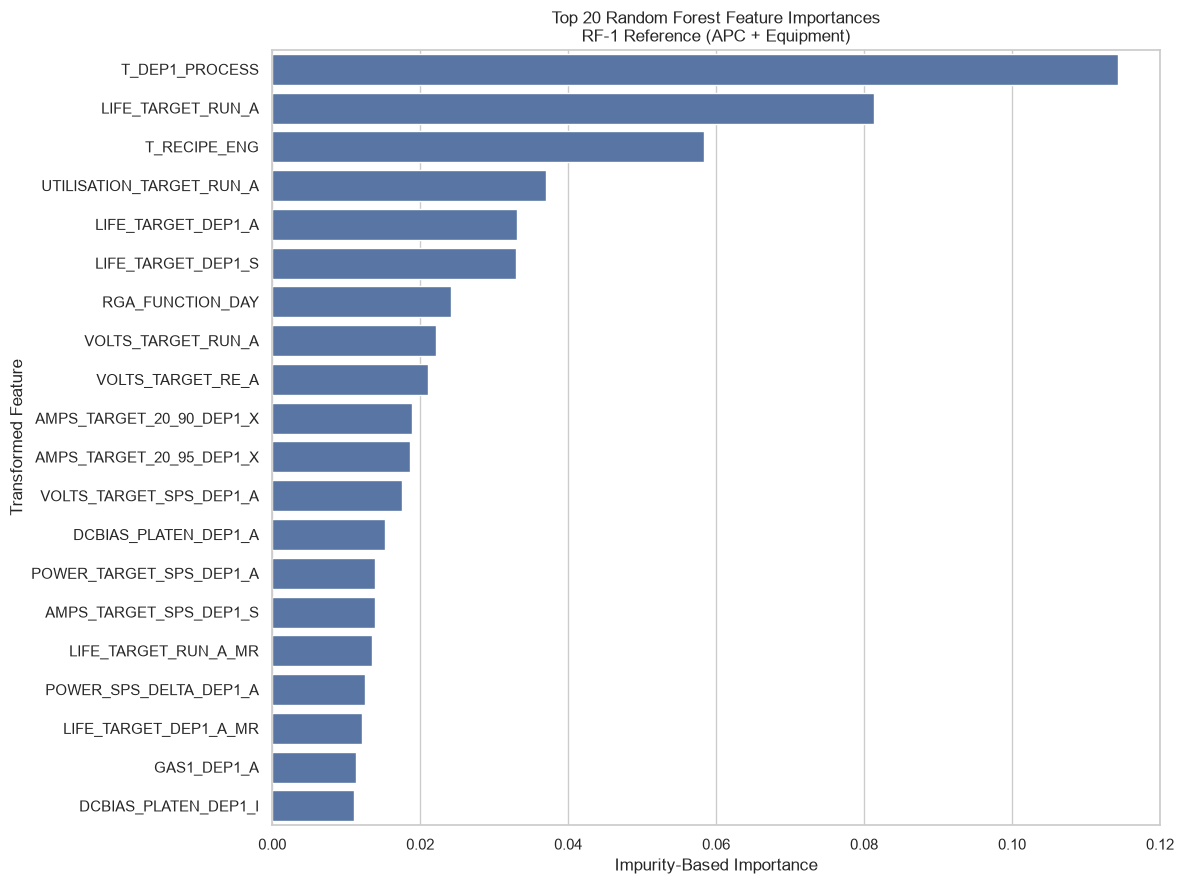

In [21]:

top_importance = importance_df.head(20).copy()

top_importance["Feature"] = (
    top_importance["Feature"]
    .str.replace(
        "numeric__",
        "",
        regex=False,
    )
    .str.replace(
        "equipment__",
        "",
        regex=False,
    )
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_importance,
    x="Importance",
    y="Feature",
)

plt.title(
    f"Top 20 Random Forest Feature Importances\n"
    f"{best_model_name}"
)

plt.xlabel("Impurity-Based Importance")
plt.ylabel("Transformed Feature")

plt.tight_layout()
plt.show()

,Importance,Importance (%)
Feature Group,,
APC Measurements,0.971499,97.149903
Equipment Metadata,0.014790,1.478984
Missingness Indicators,0.013711,1.371113


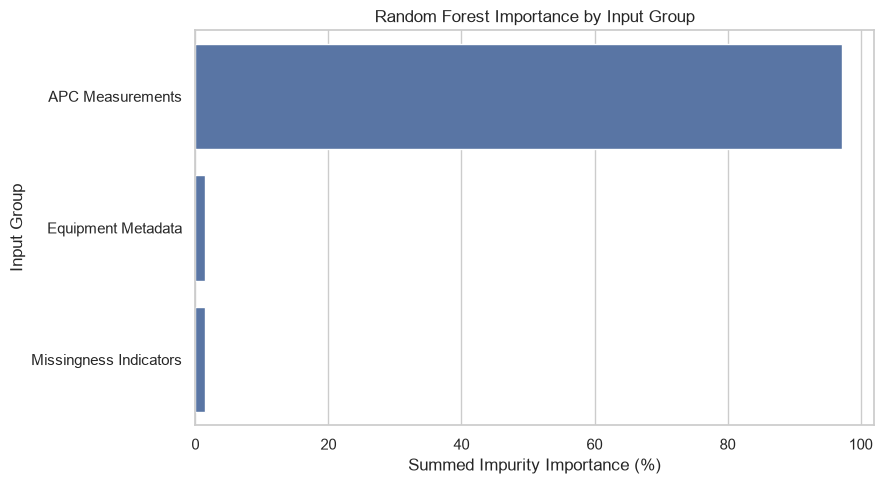

In [22]:

# Group transformed feature importance

importance_groups = importance_df.copy()

def classify_transformed_feature(name):

    if name.startswith("equipment__"):

        return "Equipment Metadata"

    if name.startswith(
        "numeric__missingindicator_"
    ):

        return "Missingness Indicators"

    return "APC Measurements"

importance_groups["Feature Group"] = (
    importance_groups["Feature"]
    .apply(classify_transformed_feature)
)

grouped_importance = (
    importance_groups
    .groupby("Feature Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .to_frame()
)

grouped_importance["Importance (%)"] = (
    grouped_importance["Importance"] * 100
)

display(
    grouped_importance.round(6)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=grouped_importance.reset_index(),
    x="Importance (%)",
    y="Feature Group",
)

plt.title(
    "Random Forest Importance by Input Group"
)

plt.xlabel("Summed Impurity Importance (%)")
plt.ylabel("Input Group")

plt.tight_layout()
plt.show()

## 14. Equipment-Level Validation Performance

Investigate Random Forest prediction errors
across manufacturing equipment identifiers.

Compare sample counts, MAE, RMSE, prediction bias,
and maximum absolute error.

Assess whether aggregate predictive performance
conceals equipment-specific weaknesses.

,Records,MAE,RMSE,Bias,Maximum_Error
equipment,,,,,
equipment_16,47,1.812130,1.991507,1.812130,3.941230
equipment_11,50,1.655560,2.237366,0.320229,6.312538
equipment_3,47,1.576697,2.211254,-0.919465,6.295494
equipment_8,54,1.427861,1.677351,0.459633,3.668726
equipment_13,54,1.400074,1.613840,1.248827,3.136942
equipment_14,56,1.399586,1.735135,-1.043172,5.567727
equipment_1,56,1.339391,1.536367,-1.154988,2.930052
equipment_15,50,1.336972,1.654364,0.532495,4.853736
equipment_7,48,1.120338,1.494486,-0.172871,4.456839


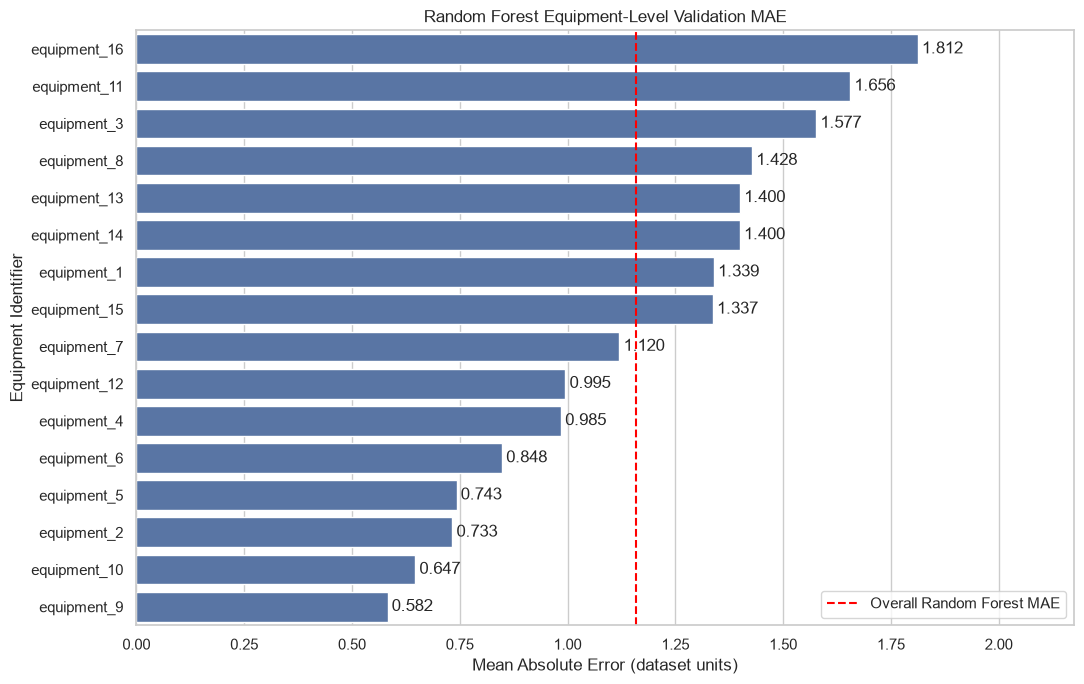

In [24]:

# STEP 3.3.18 - Equipment-level error analysis

equipment_errors = pd.DataFrame({
    "equipment": val_df["equipment"].to_numpy(),
    "Actual": y_val.to_numpy(),
    "Predicted": best_predictions,
})

equipment_errors["Absolute Error"] = (
    equipment_errors["Actual"]
    - equipment_errors["Predicted"]
).abs()

equipment_errors["Squared Error"] = (
    equipment_errors["Absolute Error"] ** 2
)

equipment_errors["Bias"] = (
    equipment_errors["Predicted"]
    - equipment_errors["Actual"]
)

equipment_error_summary = (
    equipment_errors
    .groupby("equipment")
    .agg(
        Records=("Actual", "count"),
        MAE=("Absolute Error", "mean"),
        MSE=("Squared Error", "mean"),
        Bias=("Bias", "mean"),
        Maximum_Error=("Absolute Error", "max"),
    )
)

equipment_error_summary["RMSE"] = np.sqrt(
    equipment_error_summary.pop("MSE")
)

equipment_error_summary = (
    equipment_error_summary[
        [
            "Records",
            "MAE",
            "RMSE",
            "Bias",
            "Maximum_Error",
        ]
    ]
    .sort_values("MAE", ascending=False)
)

display(
    equipment_error_summary.round(6)
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=equipment_error_summary.reset_index(),
    x="MAE",
    y="equipment",
)

ax.axvline(
    best_metrics["MAE"],
    color="red",
    linestyle="--",
    label="Overall Random Forest MAE",
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f",
    padding=3,
)

plt.xlim(
    0,
    equipment_error_summary["MAE"].max() * 1.2,
)

plt.title(
    "Random Forest Equipment-Level Validation MAE"
)

plt.xlabel("Mean Absolute Error (dataset units)")
plt.ylabel("Equipment Identifier")

plt.legend()
plt.tight_layout()
plt.show()

## 15. Model Complexity and Computational Cost

Inspect the actual depth and leaf counts of fitted
decision trees.

Compare model complexity, training time, and
validation prediction time across configurations.

Computational measurements are specific to the
hardware and software environment used.

In [25]:

# STEP 3.3.19 - Model complexity analysis

complexity_results = []

for model_name, pipeline in (
    trained_forest_models.items()
):

    forest = pipeline.named_steps["regressor"]

    tree_depths = np.array([
        tree.get_depth()
        for tree in forest.estimators_
    ])

    leaf_counts = np.array([
        tree.get_n_leaves()
        for tree in forest.estimators_
    ])

    complexity_results.append({
        "Model": model_name,
        "Trees": len(forest.estimators_),
        "Mean Tree Depth": float(
            tree_depths.mean()
        ),
        "Maximum Tree Depth": int(
            tree_depths.max()
        ),
        "Mean Leaves per Tree": float(
            leaf_counts.mean()
        ),
        "Total Tree Leaves": int(
            leaf_counts.sum()
        ),
    })

complexity_df = pd.DataFrame(
    complexity_results
)

complexity_summary = forest_results_df[
    [
        "Model",
        "MAE",
        "Training Time (s)",
        "Validation Prediction Time (s)",
    ]
].merge(
    complexity_df,
    on="Model",
    validate="one_to_one",
)

display(
    complexity_summary.round(6)
)

,Model,MAE,Training Time (s),Validation Prediction Time (s),Trees,Mean Tree Depth,Maximum Tree Depth,Mean Leaves per Tree,Total Tree Leaves
0,RF-1 Reference (APC + Equipment),1.158247,3.753886,0.113907,200,29.575,40,2103.330,420666
1,RF-1 Reference (APC Only),1.163595,3.712273,0.072484,200,29.060,39,2103.305,420661
2,RF-4 Larger Ensemble (APC Only),1.175128,4.921495,0.178495,400,12.000,12,462.290,184916
3,RF-4 Larger Ensemble (APC + Equipment),1.175634,5.224913,0.166989,400,12.000,12,460.985,184394
4,RF-2 Moderate (APC + Equipment),1.175809,2.748241,0.098529,200,12.000,12,461.620,92324
5,RF-2 Moderate (APC Only),1.176203,2.527400,0.085066,200,12.000,12,463.885,92777
6,RF-3 Regularised (APC Only),1.228910,1.858283,0.093138,200,8.000,8,104.040,20808
7,RF-3 Regularised (APC + Equipment),1.234571,2.179212,0.108325,200,8.000,8,103.695,20739


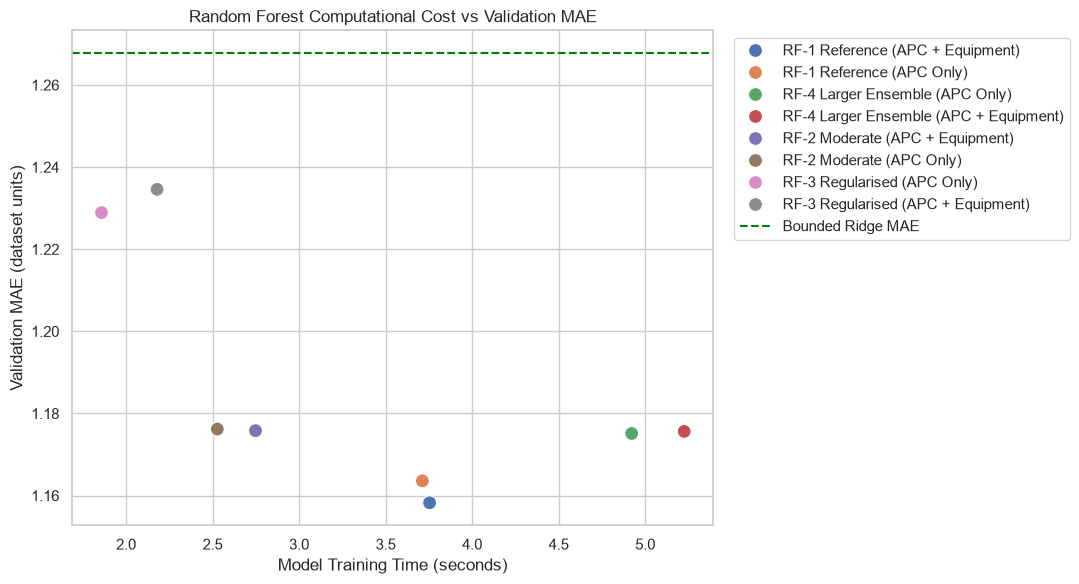

In [26]:

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=complexity_summary,
    x="Training Time (s)",
    y="MAE",
    hue="Model",
    s=100,
)

plt.axhline(
    RIDGE_MAE,
    color="green",
    linestyle="--",
    label="Bounded Ridge MAE",
)

plt.title(
    "Random Forest Computational Cost vs Validation MAE"
)

plt.xlabel("Model Training Time (seconds)")
plt.ylabel("Validation MAE (dataset units)")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

## 16. Random Forest Pipeline Verification

Verify preprocessing configurations, transformed
feature dimensions, training row counts,
prediction validity, and unknown-equipment handling.

These checks establish software integrity rather
than independent predictive performance.

In [27]:

# STEP 3.3.20A - Verify fitted pipelines

for model_name, pipeline in (
    trained_forest_models.items()
):

    preprocessor = pipeline.named_steps[
        "preprocessor"
    ]

    forest = pipeline.named_steps[
        "regressor"
    ]

    feature_names = (
        preprocessor.get_feature_names_out()
    )

    assert (
        len(feature_names)
        == forest.n_features_in_
    )

    assert (
        len(feature_names)
        == len(forest.feature_importances_)
    )

    numeric_pipeline = (
        preprocessor.named_transformers_["numeric"]
    )

    assert "imputer" in numeric_pipeline.named_steps

    assert (
        "scaler"
        not in numeric_pipeline.named_steps
    )

    assert (
        "bounded_scaling"
        not in numeric_pipeline.named_steps
    )

    imputer = numeric_pipeline.named_steps["imputer"]

    np.testing.assert_allclose(
        imputer.statistics_,
        train_df[apc_features]
        .median()
        .fillna(0)
        .to_numpy(dtype=float),
        equal_nan=True,
    )

    if "APC Only" in model_name:

        assert not any(
            name.startswith("equipment__")
            for name in feature_names
        )

    else:

        assert any(
            name.startswith("equipment__")
            for name in feature_names
        )

    predictions = validation_predictions[
        model_name
    ]

    assert np.isfinite(predictions).all()

    assert len(predictions) == len(y_val)

    assert (predictions > 0).all()

print("Random Forest pipeline verification: PASSED")

print(
    "Total verified models:",
    len(trained_forest_models)
)

Random Forest pipeline verification: PASSED
Total verified models: 8


In [28]:

# STEP 3.3.20B - Synthetic input robustness

best_equipment_forest_name = (
    forest_results_df.loc[
        forest_results_df["Configuration"]
        == "APC + Equipment"
    ]
    .sort_values("MAE")
    .iloc[0]["Model"]
)

equipment_pipeline = trained_forest_models[
    best_equipment_forest_name
]

synthetic_input = (
    train_df[feature_columns]
    .iloc[[0]]
    .copy()
)

# Simulate an unfamiliar equipment identifier
synthetic_input["equipment"] = (
    "equipment_unseen_demo"
)

# Simulate three unavailable APC measurements
missing_demo_features = apc_features[:3]

synthetic_input[missing_demo_features] = np.nan

synthetic_prediction = (
    equipment_pipeline.predict(
        synthetic_input
    )
)

assert synthetic_prediction.shape == (1,)

assert np.isfinite(
    synthetic_prediction
).all()

assert (synthetic_prediction > 0).all()

assert (
    training_target_min - range_tolerance
    <= synthetic_prediction[0]
    <= training_target_max + range_tolerance
)

print(
    "Unknown equipment and missing sensor test: PASSED"
)

print(
    "Synthetic prediction:",
    synthetic_prediction[0]
)

print(
    "Simulated unavailable features:",
    missing_demo_features
)

Unknown equipment and missing sensor test: PASSED
Synthetic prediction: 152.15949565994322
Simulated unavailable features: ['AMPS_TARGET_20_90_DELTA_DEP1', 'AMPS_TARGET_20_90_DEP1_M', 'AMPS_TARGET_20_90_DEP1_SPS']


## 17. Experiment Result Preservation

Preserve all Random Forest experiment results,
configuration details, reference benchmarks,
software versions, and prediction diagnostics.

The final test partition has not been evaluated.

No individual wafer measurements or fitted model
artifacts are exported in this step.

In [29]:

# STEP 3.3.21 - Save experiment results

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

results_path = (
    results_dir
    / "thickness_random_forest.json"
)

serializable_results = (
    forest_results_df
    .astype(object)
    .where(
        pd.notna(forest_results_df),
        None,
    )
    .to_dict(orient="records")
)

selected_max_depth = best_result["Max Depth"]

if pd.isna(selected_max_depth):

    selected_max_depth = None

else:

    selected_max_depth = int(
        selected_max_depth
    )

experiment_results = {
    "project": "STRATUM",
    "experiment": "thickness_random_forest",
    "target": TARGET,
    "dataset_sha256": current_sha256,
    "evaluation_partition": "validation",
    "training_records": len(train_df),
    "validation_records": len(val_df),
    "primary_metric": "MAE",
    "reference_baseline": "Equipment Mean",
    "reference_baseline_mae": BASELINE_MAE,
    "reference_ridge_mae": RIDGE_MAE,
    "reference_ridge_rmse": RIDGE_RMSE,
    "reference_ridge_r2": RIDGE_R2,
    "random_state": RANDOM_STATE,
    "n_jobs": N_JOBS,
    "sklearn_version": sklearn.__version__,
    "max_features": MAX_FEATURES,
    "feature_configurations": list(
        feature_configurations.keys()
    ),
    "forest_configurations": forest_configurations,
    "total_experiments": len(forest_results_df),
    "best_model": best_model_name,
    "best_model_parameters": {
        "include_equipment": (
            best_result["Configuration"]
            == "APC + Equipment"
        ),
        "n_estimators": int(
            best_result["Trees"]
        ),
        "max_depth": selected_max_depth,
        "min_samples_leaf": int(
            best_result["Min Samples Leaf"]
        ),
        "max_features": MAX_FEATURES,
        "random_state": RANDOM_STATE,
    },
    "best_model_mae": float(
        best_result["MAE"]
    ),
    "best_model_rmse": float(
        best_result["RMSE"]
    ),
    "best_model_r2": float(
        best_result["R2"]
    ),
    "best_model_maximum_absolute_error": float(
        best_result["Maximum Absolute Error"]
    ),
    "best_model_non_positive_predictions": int(
        best_result["Non-Positive Predictions"]
    ),
    "best_model_improvement_vs_baseline_pct": float(
        best_result[
            "MAE Improvement vs Baseline (%)"
        ]
    ),
    "best_model_improvement_vs_ridge_pct": float(
        best_result[
            "MAE Improvement vs Ridge (%)"
        ]
    ),
    "sensor_warning_bound": WARNING_BOUND,
    "sensor_warning_count": int(
        warning_error_df["Sensor Warning"].sum()
    ),
    "results": serializable_results,
    "equipment_error_summary": (
        equipment_error_summary
        .reset_index()
        .to_dict(orient="records")
    ),
    "complexity_summary": (
        complexity_df.to_dict(orient="records")
    ),
}

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        experiment_results,
        file,
        indent=4,
        allow_nan=False,
    )

print("Random Forest experiment results saved.")

print("ml/results/thickness_random_forest.json")

Random Forest experiment results saved.
ml/results/thickness_random_forest.json



## 18. Findings and Engineering Interpretation

### Model Development

Developed reusable Random Forest Regression pipelines
for semiconductor virtual metrology.

Evaluated eight experiments across two input
configurations and four forest configurations.

### Preprocessing

- Training-only numerical median imputation.
- Missingness indicator generation.
- Optional equipment one-hot encoding.
- No numerical standardisation.
- No bounded-standardisation clipping.
- End-to-end preprocessing and regression pipelines.

### Reference Benchmarks

Equipment Mean:
- MAE: 1.995479
- RMSE: 2.444380
- R2: -0.001596

Bounded Ridge:
- MAE: 1.267788
- RMSE: 1.673137
- R2: 0.530735

### Quantitative Findings

Complete using the actual executed experiment results:

- Best Random Forest configuration:
- Equipment metadata included:
- Number of trees:
- Maximum depth:
- Minimum leaf samples:
- Training MAE:
- Validation MAE:
- Validation RMSE:
- Validation R2:
- Validation MAPE:
- Prediction bias:
- Maximum absolute error:
- 95th percentile absolute error:
- MAE improvement over equipment baseline:
- MAE improvement over bounded Ridge:

### Generalisation Analysis

Compare training and validation error.

Investigate whether highly complex forests achieve
lower training errors but weaker validation performance.

Acknowledge that the chronological generalisation
gap may reflect both overfitting and temporal shifts.

### Equipment Metadata Ablation

Record whether including explicit equipment metadata
improves validation performance in the paired
Random Forest experiments.

APC-only models may still capture equipment-related
information indirectly through process measurements
and missingness patterns.

### Prediction Robustness

Record the prediction range checks and number
of non-positive predictions.

Compare the two previous catastrophic Ridge prediction
cases with their Random Forest predictions.

### Input Distribution Diagnostics

Compare prediction errors for records with and
without the previous numerical sensor warning.

The warning heuristic is not a calibrated prediction
uncertainty estimator or engineering alarm threshold.

### Feature Importance

Document the most influential transformed features
according to impurity-based importance.

Compare importance attributed to measurements,
missingness indicators, and equipment metadata.

Feature importance does not establish physical causality.

### Equipment-Level Performance

Document equipment-specific differences in MAE,
RMSE, prediction bias, and maximum absolute error.

Interpret the results alongside equipment sample counts.

### Computational Cost

Compare the fitted ensemble sizes, tree complexity,
training time, and validation prediction time.

### Limitations

- The hyperparameter search is preliminary.
- Validation results are used for model selection.
- The final test partition has not been evaluated.
- Random Forest cannot reliably extrapolate beyond
  the training target range.
- Prediction positivity does not ensure accuracy.
- Impurity importance has known interpretation limits.
- Equipment generalisation has not been established.
- Earlier exploratory analysis examined the full dataset.
- Process input availability at the intended prediction
  time requires further verification.

### Conclusion

Random Forest provides a nonlinear virtual metrology
approach for semiconductor mean-thickness prediction.

Its predictive value must be assessed against
historical baselines and bounded Ridge Regression.

The next step investigates gradient-boosted
regression using XGBoost.